<a href="https://colab.research.google.com/github/SanskritiVij/tp53-mutation-analysis/blob/main/TP53_subtype_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

mut = pd.read_csv("data_mutations.txt", sep="\t", comment="#", low_memory=False,
                  usecols=["Hugo_Symbol", "Variant_Classification", "Tumor_Sample_Barcode"])
clin = pd.read_csv("data_clinical_patient.txt", sep="\t", comment="#")
print(mut.shape, clin.shape)
print(clin.columns.tolist())

(126252, 3) (1084, 38)
['PATIENT_ID', 'SUBTYPE', 'CANCER_TYPE_ACRONYM', 'OTHER_PATIENT_ID', 'AGE', 'SEX', 'AJCC_PATHOLOGIC_TUMOR_STAGE', 'AJCC_STAGING_EDITION', 'DAYS_LAST_FOLLOWUP', 'DAYS_TO_BIRTH', 'DAYS_TO_INITIAL_PATHOLOGIC_DIAGNOSIS', 'ETHNICITY', 'FORM_COMPLETION_DATE', 'HISTORY_NEOADJUVANT_TRTYN', 'ICD_10', 'ICD_O_3_HISTOLOGY', 'ICD_O_3_SITE', 'INFORMED_CONSENT_VERIFIED', 'NEW_TUMOR_EVENT_AFTER_INITIAL_TREATMENT', 'PATH_M_STAGE', 'PATH_N_STAGE', 'PATH_T_STAGE', 'PERSON_NEOPLASM_CANCER_STATUS', 'PRIMARY_LYMPH_NODE_PRESENTATION_ASSESSMENT', 'PRIOR_DX', 'RACE', 'RADIATION_THERAPY', 'WEIGHT', 'IN_PANCANPATHWAYS_FREEZE', 'OS_STATUS', 'OS_MONTHS', 'DSS_STATUS', 'DSS_MONTHS', 'DFS_STATUS', 'DFS_MONTHS', 'PFS_STATUS', 'PFS_MONTHS', 'GENETIC_ANCESTRY_LABEL']


In [2]:
print(clin["SUBTYPE"].value_counts(dropna=False))

SUBTYPE
BRCA_LumA      499
BRCA_LumB      197
BRCA_Basal     171
NaN            103
BRCA_Her2       78
BRCA_Normal     36
Name: count, dtype: int64


In [3]:
mut["PATIENT_ID"] = mut["Tumor_Sample_Barcode"].str[:12]
tp53 = mut[(mut["Hugo_Symbol"] == "TP53") & (mut["Variant_Classification"] != "Silent")]
tp53_patients = set(tp53["PATIENT_ID"])

clin = clin[clin["PATIENT_ID"].isin(mut["PATIENT_ID"])].copy()
clin["TP53_mutant"] = clin["PATIENT_ID"].isin(tp53_patients)
print(clin["TP53_mutant"].value_counts())

TP53_mutant
False    661
True     348
Name: count, dtype: int64


In [4]:
sub = clin.dropna(subset=["SUBTYPE"]).copy()
rate = sub.groupby("SUBTYPE")["TP53_mutant"].agg(["sum", "count"])
rate.columns = ["TP53_mutant", "patients"]
rate["percent"] = (100 * rate["TP53_mutant"] / rate["patients"]).round(1)
print(rate.sort_values("percent", ascending=False))

             TP53_mutant  patients  percent
SUBTYPE                                    
BRCA_Basal           154       171     90.1
BRCA_Her2             55        78     70.5
BRCA_LumB             71       197     36.0
BRCA_Normal           11        36     30.6
BRCA_LumA             53       499     10.6


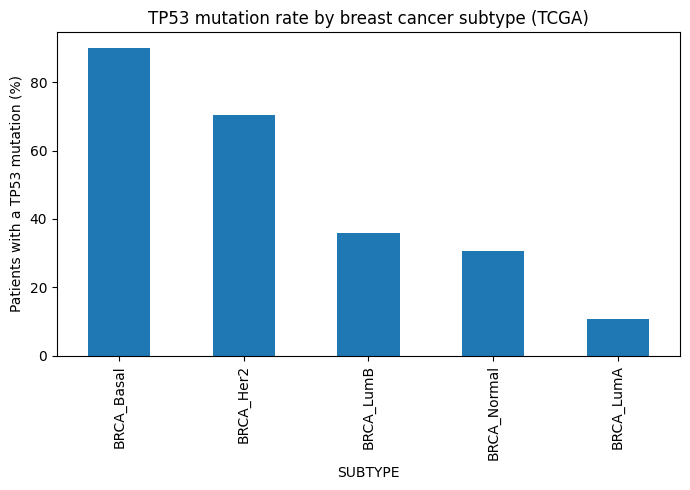

In [5]:
rate["percent"].sort_values(ascending=False).plot(kind="bar", figsize=(7, 5))
plt.title("TP53 mutation rate by breast cancer subtype (TCGA)")
plt.ylabel("Patients with a TP53 mutation (%)")
plt.tight_layout()
plt.savefig("tp53_by_subtype.png", dpi=200)
plt.show()

I calculated the share of patients with a TP53 mutation within each breast cancer subtype, using the 981 patients who have a subtype listed. Basal-like tumors had the highest rate (154 of 171, 90.1%), followed by HER2-enriched (55 of 78, 70.5%), Luminal B (71 of 197, 36.0%), Normal-like (11 of 36, 30.6%) and Luminal A (53 of 499, 10.6%). The overall rate of 34.5% hides a large difference between subtypes. Luminal A makes up about about 70% of the wild-type patients with a subtype listed but only 15% of the mutant patients, so my earlier survival comparison mixed subtype with mutation status. Normal-like has only 36 patients, so its rate is uncertain.

In [6]:
!pip install lifelines -q
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

clin["OS_MONTHS"] = pd.to_numeric(clin["OS_MONTHS"], errors="coerce")
surv = clin.dropna(subset=["SUBTYPE", "OS_STATUS", "OS_MONTHS"]).copy()
surv["event"] = surv["OS_STATUS"].str.startswith("1").astype(int)

rows = []
for st, g in surv.groupby("SUBTYPE"):
    m, w = g[g["TP53_mutant"]], g[~g["TP53_mutant"]]
    if len(m) >= 10 and len(w) >= 10 and g["event"].sum() >= 10:
        p = logrank_test(m["OS_MONTHS"], w["OS_MONTHS"], m["event"], w["event"]).p_value
        rows.append([st, len(m), len(w), int(g["event"].sum()), round(p, 3)])
print(pd.DataFrame(rows, columns=["subtype", "mutant", "wild_type", "deaths", "p_value"]))

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 21.2 MB/s eta 0:00:00
      subtype  mutant  wild_type  deaths  p_value
0  BRCA_Basal     154         17      22    0.567
1   BRCA_Her2      55         23      15    0.016
2   BRCA_LumA      53        446      57    0.377
3   BRCA_LumB      71        126      31    0.556


BRCA_LumA TP53 wild-type patients: 446 deaths: 50 survival at 60 months: 0.87
BRCA_LumA TP53 mutant patients: 53 deaths: 7 survival at 60 months: 0.89
BRCA_LumB TP53 wild-type patients: 126 deaths: 19 survival at 60 months: 0.81
BRCA_LumB TP53 mutant patients: 71 deaths: 12 survival at 60 months: 0.69
BRCA_Basal TP53 wild-type patients: 17 deaths: 1 survival at 60 months: 0.88
BRCA_Basal TP53 mutant patients: 154 deaths: 21 survival at 60 months: 0.83
BRCA_Her2 TP53 wild-type patients: 23 deaths: 7 survival at 60 months: 0.54
BRCA_Her2 TP53 mutant patients: 55 deaths: 8 survival at 60 months: 0.84


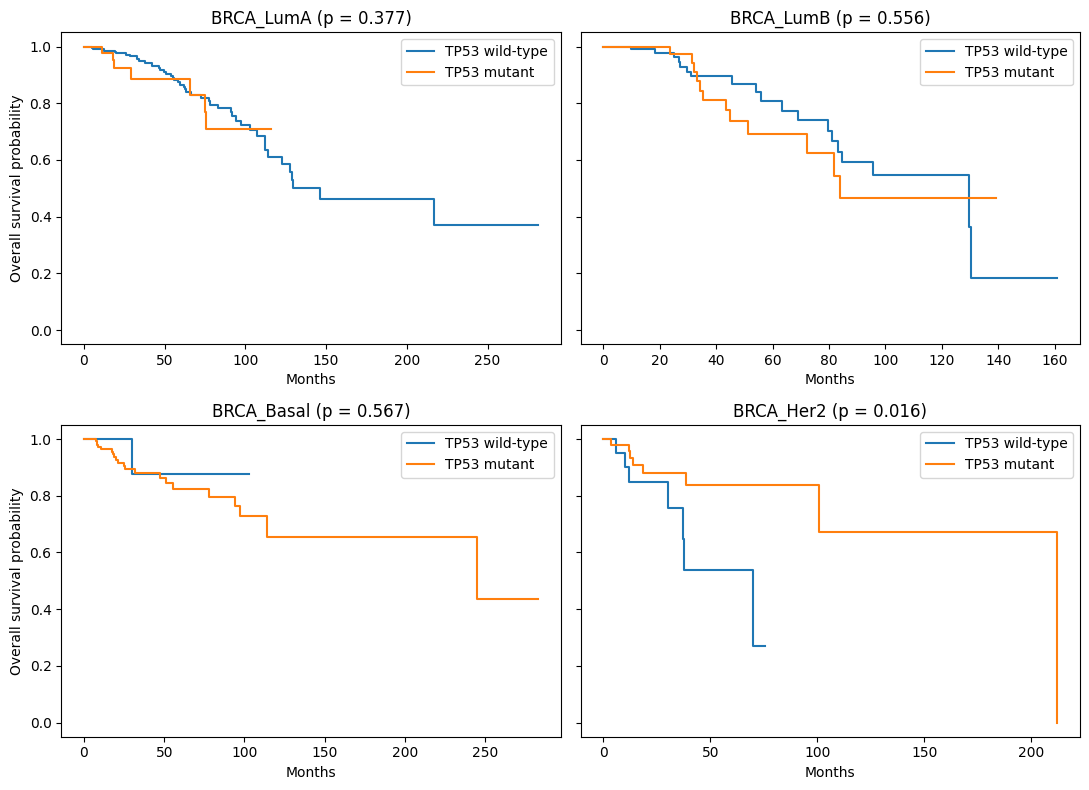

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
kmf = KaplanMeierFitter()
pvals = dict(zip([r[0] for r in rows], [r[4] for r in rows]))
for ax, st in zip(axes.flatten(), ["BRCA_LumA", "BRCA_LumB", "BRCA_Basal", "BRCA_Her2"]):
    g = surv[surv["SUBTYPE"] == st]
    for flag, grp in g.groupby("TP53_mutant"):
        label = "TP53 mutant" if flag else "TP53 wild-type"
        kmf.fit(grp["OS_MONTHS"], grp["event"], label=label)
        kmf.plot_survival_function(ax=ax, ci_show=False)
        print(st, label, "patients:", len(grp), "deaths:", int(grp["event"].sum()), "survival at 60 months:", round(float(kmf.predict(60)), 2))
    ax.set_title(st + " (p = " + str(pvals[st]) + ")")
    ax.set_xlabel("Months")
axes[0][0].set_ylabel("Overall survival probability")
axes[1][0].set_ylabel("Overall survival probability")
plt.tight_layout()
plt.savefig("tp53_survival_by_subtype.png", dpi=200)
plt.show()

In [9]:
from google.colab import files
files.download("tp53_by_subtype.png")
files.download("tp53_survival_by_subtype.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Within each subtype, I compared overall survival between TP53-mutant and wild-type patients using a log-rank test. In Luminal A (p = 0.38), Luminal B (p = 0.56) and Basal-like (p = 0.57) there was no significant difference. In HER2-enriched tumors the p-value was 0.016, with the mutant group doing [better or worse], [x]% alive at 60 months against [y]% for wild-type. This rests on 15 deaths and only 23 wild-type patients. I ran four tests and the group is small, so I treat this as a possible signal that needs a larger cohort. Basal-like had only 17 wild-type patients, so that comparison has little power. Normal-like was left out because it had too few patients.